**Nama:** David Gaby Sahala Sinambela
**NIM:** 2802520293

Notebook untuk Part B dari GSLC Deep Learning
Isi notebook:
0. Setup environment dan folder output
1. Konfigurasi eksperimen dan seed
2. Dataset Oxford-IIIT Pet (10 kelas, split 70/15/15)
3. Pipeline transformasi (augmentasi cuma di train set)
4. Model builder dan cek trainable parameters
5. Training loop, early stopping, dan logging
6. Eksperimen B1 sampai B5
7. Tabel konsolidasi dan kurva loss (bahan C1)
8. Analisis augmentasi B4 (bahan C2)
9. Failure analysis model terbaik (bahan C3)
10. Daftar file output

Cara Menjalanakan: Download file ini lalu buka Google Colab. Jangan lupa untuk pilih Runtime yang sesuai (T4 GPU). lalu Run All



## 1. Enviroment
Bagian untuk import semua library yang bakal dipakai. 
Python, PyTorch, torchvision, dan GPU yang aktif. 

- Untuk lebih detail ada 'requirements.txt' untuk konfigurasi environment yang saya pakai.


In [1]:
# Setup Environment
import os, json, time, copy, random, platform
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
from IPython.display import display

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader, ConcatDataset
import torchvision
from torchvision import models, transforms
from torchvision.datasets import OxfordIIITPet
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Python      :", platform.python_version())
print("PyTorch     :", torch.__version__)
print("torchvision :", torchvision.__version__)
print("Device      :", DEVICE, "-", torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "CPU")

Python      : 3.13.15
PyTorch     : 2.11.0+cu130
torchvision : 0.26.0+cu130
Device      : cuda - Tesla T4


Log & Checkpoin akan disimpan di Google Drive. Alasan saya menggunakan metode ini adalah:
- Supaya kalau runntime colab terputus, hasil run yang sudah selsai tidak ikut hilang

Kalau tidak mau pakai Drive, ubah USE_DRIVE menjadi = False dan output akan tersimpan di folder local


In [ ]:
USE_DRIVE = True

try:
    from google.colab import drive
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if USE_DRIVE and IN_COLAB:
    drive.mount("/content/drive")
    OUT_DIR = Path("/content/drive/MyDrive/tugas05_outputs")
else:
    OUT_DIR = Path("outputs")

DATA_ROOT = Path("/content/data") if IN_COLAB else Path("data")
RUNS_DIR = OUT_DIR / "runs"
CKPT_DIR = OUT_DIR / "checkpoints"
FIG_DIR = OUT_DIR / "figures"
for d in (OUT_DIR, RUNS_DIR, CKPT_DIR, FIG_DIR, DATA_ROOT):
    d.mkdir(parents=True, exist_ok=True)
print("Output folder:", OUT_DIR.resolve())

Mounted at /content/drive
Output folder: /content/drive/MyDrive/tugas05_outputs


## 2. Konfigurasi Eksperimen dan Reproduksibilitas

Saya mengikuti petunjuk dan instruksi untuk bagian Hyperparameter tentunya ada beberapa yang tidak ada di soal jadinya saya menggunakan default value yang saya tentukan sendiri

| Keputusan | Nilai | Alasan |
|---|---|---|
| Augmentasi di B1–B3 | Aktif (sesuai starter code) | Supaya B1, B2, dan B3 dibandingkan dengan pipeline data yang sama |
| Learning rate B1 | `1e-3` untuk semua layer | Nilai standar AdamW untuk training dari nol |
| Learning rate B2 | `1e-3` untuk `fc` | Disamakan dengan LR head di B3 supaya perbandingannya adil |
| Learning rate B3 | `1e-4` (`layer4`), `1e-3` (`fc`) | Differential learning rate sesuai PDF |
| Early stopping | Monitor val loss, patience 5, maksimal 30 epoch | Patience masih di rentang 3–5 sesuai PDF |
| Bobot untuk evaluasi | Checkpoint dengan val loss terbaik | Test set cuma dievaluasi sekali per run |
| BatchNorm di layer yang dibekukan | Mode `eval()` | `requires_grad=False` saja tidak menghentikan update running mean/var BN |
| Dasar B4 | Konfigurasi B3 | Parameter yang dibuka lebih banyak, jadi efek overfitting dan augmentasi lebih kelihatan |
| Arsitektur B5 | EfficientNet-B0 (Slide 24) | Konfigurasi terbaik dipilih dari val accuracy, bukan dari test |

Untuk Class yang dipilih: 5 kucing dan 5 anjing. Saya memasukkan tiga pasangan ras yang mirip. Efeknya, tugas jadi lebih susah, tapi failure analysis di C3 akan membuat lebih berbobot karena ada kasus yang membingungkan


In [3]:
SEED = 42
BATCH_SIZE = 32
MAX_EPOCHS = 30
PATIENCE = 5             # early stopping: berhenti jika val loss tidak membaik 5 epoch berturut-turut
WEIGHT_DECAY = 1e-2
LR_SCRATCH = 1e-3        # B1: seluruh parameter
LR_HEAD = 1e-3           # classifier head (B2, B3, B4, B5)
LR_BACKBONE = 1e-4       # blok backbone yang dibuka (B3, B4, B5)
NUM_WORKERS = 2
RESUME = False           # True hanya jika runtime terputus: run yang sudah selesai dimuat dari Drive

CAT_BREEDS = ["Abyssinian", "Birman", "British Shorthair", "Ragdoll", "Russian Blue"]
DOG_BREEDS = ["American Pit Bull Terrier", "Beagle", "Samoyed", "Shiba Inu", "Staffordshire Bull Terrier"]
SELECTED_CLASSES = CAT_BREEDS + DOG_BREEDS
NUM_CLASSES = len(SELECTED_CLASSES)


def set_seed(seed: int = SEED) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


set_seed(SEED)

CONFIG = {
    "seed": SEED, "batch_size": BATCH_SIZE, "max_epochs": MAX_EPOCHS, "patience": PATIENCE,
    "optimizer": "AdamW", "weight_decay": WEIGHT_DECAY, "loss": "CrossEntropyLoss",
    "lr_scratch": LR_SCRATCH, "lr_head": LR_HEAD, "lr_backbone": LR_BACKBONE,
    "input_size": 224, "normalization": {"mean": [0.485, 0.456, 0.406], "std": [0.229, 0.224, 0.225]},
    "selected_classes": SELECTED_CLASSES, "split": {"train": 0.70, "val": 0.15, "test": 0.15},
    "torch": torch.__version__, "torchvision": torchvision.__version__,
}
with open(OUT_DIR / "config.json", "w") as f:
    json.dump(CONFIG, f, indent=2)
print(json.dumps(CONFIG, indent=2))

{
  "seed": 42,
  "batch_size": 32,
  "max_epochs": 30,
  "patience": 5,
  "optimizer": "AdamW",
  "weight_decay": 0.01,
  "loss": "CrossEntropyLoss",
  "lr_scratch": 0.001,
  "lr_head": 0.001,
  "lr_backbone": 0.0001,
  "input_size": 224,
  "normalization": {
    "mean": [
      0.485,
      0.456,
      0.406
    ],
    "std": [
      0.229,
      0.224,
      0.225
    ]
  },
  "selected_classes": [
    "Abyssinian",
    "Birman",
    "British Shorthair",
    "Ragdoll",
    "Russian Blue",
    "American Pit Bull Terrier",
    "Beagle",
    "Samoyed",
    "Shiba Inu",
    "Staffordshire Bull Terrier"
  ],
  "split": {
    "train": 0.7,
    "val": 0.15,
    "test": 0.15
  },
  "torch": "2.11.0+cu130",
  "torchvision": "0.26.0+cu130"
}


## 3. Dataset: Oxford-IIIT Pet (10 Kelas, Split 70/15/15)

Torchvision sudah membagi dataset ini jadi `trainval` dan `test`. Dua split itu digabung dulu, lalu dibagi ulang secara stratified sesuai aturan PDF. Label aslinya ada 37 kelas (0–36), jadi nanti dipetakan ulang ke 0–9 supaya cocok dengan `nn.Linear(512, 10)`.

Label dibaca dari atribut `_labels` dan `_bin_labels` milik torchvision, yaitu hasil baca file anotasi resminya. Cara ini lebih cepat daripada harus membuka ±7.300 gambar cuma untuk tahu labelnya. Supaya aman, kecocokannya dicek lagi dengan spot check di cell berikutnya.

In [4]:
meta_splits = [OxfordIIITPet(DATA_ROOT, split=s, target_types="category", download=True) for s in ("trainval", "test")]
class_names = meta_splits[0].classes
assert class_names == meta_splits[1].classes, "Daftar kelas split trainval dan test berbeda"

all_labels = np.array(meta_splits[0]._labels + meta_splits[1]._labels)          # 0..36
all_species = np.array(meta_splits[0]._bin_labels + meta_splits[1]._bin_labels)  # 0 = Cat, 1 = Dog
full_meta = ConcatDataset(meta_splits)   # tanpa transform: dipakai untuk spot check & menampilkan gambar asli

overview = pd.DataFrame({
    "class": class_names,
    "species": [meta_splits[0].bin_classes[all_species[all_labels == i][0]] for i in range(len(class_names))],
    "n_images": [int((all_labels == i).sum()) for i in range(len(class_names))],
})
print(f"Total gambar (trainval + test): {len(all_labels)}")
display(overview)

100%|██████████| 792M/792M [00:03<00:00, 220MB/s]
100%|██████████| 19.2M/19.2M [00:00<00:00, 104MB/s] 


Total gambar (trainval + test): 7349


,class,species,n_images
0,Abyssinian,Cat,198
1,American Bulldog,Dog,200
2,American Pit Bull Terrier,Dog,200
3,Basset Hound,Dog,200
4,Beagle,Dog,200
5,Bengal,Cat,200
6,Birman,Cat,200
7,Bombay,Cat,184
8,Boxer,Dog,199
9,British Shorthair,Cat,200


Melakukan pengecekan untuk Class yang dipilih apakah ada di dataset yang benar. Setelah itu index dari 10 class akan diambil, lalu 5 gambar diacak secara random apakah labelnya sama dengan label yang di return oleh dataset

In [5]:
for name in SELECTED_CLASSES:
    assert name in class_names, f"Kelas '{name}' tidak ditemukan. Pilihan yang tersedia: {class_names}"
species_of = dict(zip(overview["class"], overview["species"]))
assert all(species_of[c] == "Cat" for c in CAT_BREEDS), "CAT_BREEDS memuat ras yang bukan kucing"
assert all(species_of[d] == "Dog" for d in DOG_BREEDS), "DOG_BREEDS memuat ras yang bukan anjing"

orig_to_new = {class_names.index(name): new for new, name in enumerate(SELECTED_CLASSES)}
indices = np.where(np.isin(all_labels, list(orig_to_new)))[0]
y_all = np.array([orig_to_new[l] for l in all_labels[indices]])

# Spot check: label dari file anotasi == label yang dikembalikan dataset
rng = np.random.default_rng(SEED)
for gi in rng.choice(indices, size=5, replace=False):
    assert full_meta[int(gi)][1] == all_labels[gi]
print(f"Subset {NUM_CLASSES} kelas: {len(indices)} gambar. Spot check label: OK")

Subset 10 kelas: 1987 gambar. Spot check label: OK


**Split training & testing**: 70% train & 30 % untuk sisa (Validation & Testing)
Dua-duanya pakai stratify supaya proporsi tiap kelas tetap sama di semua split. Ada juga assert untuk memastikan tidak ada gambar yang muncul di lebih dari satu split, artinya tidak ada data leakage. Indeks split disimpan ke split_indices.json supaya pembagiannya bisa dicek ulang.

In [6]:
idx_train, idx_tmp, y_train, y_tmp = train_test_split(
    indices, y_all, test_size=0.30, stratify=y_all, random_state=SEED)
idx_val, idx_test, y_val, y_test = train_test_split(
    idx_tmp, y_tmp, test_size=0.50, stratify=y_tmp, random_state=SEED)

# Cek kebocoran data: tidak ada gambar yang muncul di lebih dari satu split
assert not (set(idx_train) & set(idx_val)) and not (set(idx_train) & set(idx_test)) and not (set(idx_val) & set(idx_test))
assert len(idx_train) + len(idx_val) + len(idx_test) == len(indices)

split_counts = pd.DataFrame({
    "class": SELECTED_CLASSES,
    "train": np.bincount(y_train, minlength=NUM_CLASSES),
    "val": np.bincount(y_val, minlength=NUM_CLASSES),
    "test": np.bincount(y_test, minlength=NUM_CLASSES),
})
split_counts.loc["Total"] = ["Total", len(idx_train), len(idx_val), len(idx_test)]
display(split_counts)

with open(OUT_DIR / "split_indices.json", "w") as f:
    json.dump({"classes": SELECTED_CLASSES,
               "train": idx_train.tolist(), "val": idx_val.tolist(), "test": idx_test.tolist()}, f)
split_counts.to_csv(OUT_DIR / "split_counts.csv", index=False)
print("Split disimpan ke split_indices.json. Tidak ada overlap antar split.")

,class,train,val,test
0,Abyssinian,138,30,30
1,Birman,140,30,30
2,British Shorthair,140,30,30
3,Ragdoll,140,30,30
4,Russian Blue,140,30,30
5,American Pit Bull Terrier,140,30,30
6,Beagle,140,30,30
7,Samoyed,140,30,30
8,Shiba Inu,140,30,30
9,Staffordshire Bull Terrier,132,28,29


Split disimpan ke split_indices.json. Tidak ada overlap antar split.


## 4. Pipeline Transformasi
Ada 2 jenis transformasi:
- `train_tf_aug`: augmentasi **cuma untuk data latih** (sama seperti starter code).
- `eval_tf`: tanpa augmentasi, dipakai untuk validation, test, dan B4 tanpa augmentasi.

Dataset dibuat 2 versi (pakai augmentasi & tanpa augmentasi) dengan urutan yang sama, supaya augmentasi tidak bocor ke validation/test. Augmentasi jalan on-the-fly, jadi gambar latih sedikit berbeda di tiap epoch.

In [7]:
weights_r18 = models.ResNet18_Weights.IMAGENET1K_V1
eval_tf = weights_r18.transforms()

train_tf_aug = transforms.Compose([
    transforms.Resize(256),
    transforms.RandomResizedCrop(224, scale=(0.8, 1.0)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean=eval_tf.mean, std=eval_tf.std),
])
print("eval_tf:", eval_tf)


class PetSubset(Dataset):
    # Subset dengan label 0..9; juga mengembalikan indeks global untuk log prediksi.
    def __init__(self, base, idx, label_map):
        self.base, self.idx, self.label_map = base, [int(i) for i in idx], label_map

    def __len__(self):
        return len(self.idx)

    def __getitem__(self, i):
        gi = self.idx[i]
        img, label = self.base[gi]
        return img, self.label_map[label], gi


def make_base(tf):
    return ConcatDataset([OxfordIIITPet(DATA_ROOT, split=s, target_types="category", transform=tf)
                          for s in ("trainval", "test")])


base_aug, base_eval = make_base(train_tf_aug), make_base(eval_tf)
DATASETS = {
    "train_aug": PetSubset(base_aug, idx_train, orig_to_new),
    "train_noaug": PetSubset(base_eval, idx_train, orig_to_new),   # juga dipakai untuk akurasi train "bersih"
    "val": PetSubset(base_eval, idx_val, orig_to_new),
    "test": PetSubset(base_eval, idx_test, orig_to_new),
}
print({k: len(v) for k, v in DATASETS.items()})


def seed_worker(worker_id):
    worker_seed = torch.initial_seed() % 2**32
    np.random.seed(worker_seed)
    random.seed(worker_seed)


def make_loader(ds, shuffle):
    g = torch.Generator()
    g.manual_seed(SEED)
    return DataLoader(ds, batch_size=BATCH_SIZE, shuffle=shuffle, num_workers=NUM_WORKERS,
                      pin_memory=(DEVICE.type == "cuda"), worker_init_fn=seed_worker, generator=g)

eval_tf: ImageClassification(
    crop_size=[224]
    resize_size=[256]
    mean=[0.485, 0.456, 0.406]
    std=[0.229, 0.224, 0.225]
    interpolation=InterpolationMode.BILINEAR
)
{'train_aug': 1390, 'train_noaug': 1390, 'val': 298, 'test': 299}


Cek visual: baris atas = data latih (sudah diaugmentasi), baris bawah = data validasi (tanpa augmentasi).

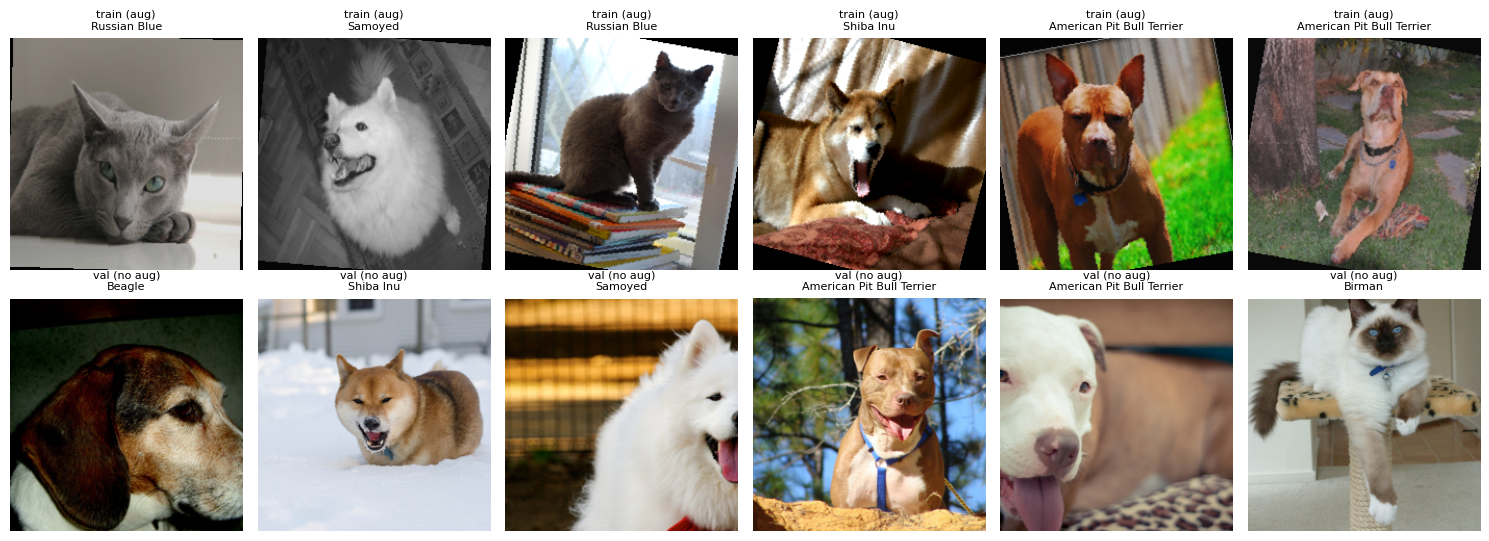

In [8]:
# Sanity check visual: data latih dengan augmentasi vs data validasi tanpa augmentasi
MEAN, STD = torch.tensor(eval_tf.mean).view(3, 1, 1), torch.tensor(eval_tf.std).view(3, 1, 1)
denorm = lambda t: (t * STD + MEAN).clamp(0, 1).permute(1, 2, 0).numpy()

fig, axes = plt.subplots(2, 6, figsize=(15, 5.5))
for j in range(6):
    img, lab, _ = DATASETS["train_aug"][j]
    axes[0, j].imshow(denorm(img)); axes[0, j].set_title(f"train (aug)\n{SELECTED_CLASSES[lab]}", fontsize=8)
    img, lab, _ = DATASETS["val"][j]
    axes[1, j].imshow(denorm(img)); axes[1, j].set_title(f"val (no aug)\n{SELECTED_CLASSES[lab]}", fontsize=8)
for ax in axes.flat:
    ax.axis("off")
plt.tight_layout()
plt.savefig(FIG_DIR / "sample_batches.png", dpi=120)
plt.show()

## 5. Model Builder dan Cek Trainable Parameters

| Strategi | Bagian yang dilatih | Learning rate |
|---|---|---|
| `scratch` (B1) | Semua layer (bobot acak) | `1e-3` |
| `feature_extraction` (B2) | `fc` saja | `1e-3` |
| `finetune` (B3, B4) | `layer4` + `fc` | `1e-4` / `1e-3` |

- Trainable parameters dicek dulu sebelum optimizer dibuat. Kalau backbone dibekukan, hasilnya harus **5.130**.
- BatchNorm di layer yang beku di-set ke `eval()`, supaya running mean/var tidak ikut berubah.
- Untuk B5, padanan `layer4` di EfficientNet-B0 adalah `features[6:]`.

In [9]:
EXPECTED_TRAINABLE_R18 = {"scratch": 11_181_642, "feature_extraction": 5_130, "finetune": 8_398_858}


def count_params(model):
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    total = sum(p.numel() for p in model.parameters())
    return trainable, total


def freeze_bn_stats(modules):
    for module in modules:
        for m in module.modules():
            if isinstance(m, nn.modules.batchnorm._BatchNorm):
                m.eval()


def build_resnet18(strategy):
    # Returns (model, param_groups, frozen_modules)
    if strategy == "scratch":
        model = models.resnet18(weights=None)
        model.fc = nn.Linear(model.fc.in_features, NUM_CLASSES)
        return model, [{"name": "all", "params": list(model.parameters()), "lr": LR_SCRATCH}], []

    model = models.resnet18(weights=weights_r18)
    for p in model.parameters():
        p.requires_grad = False
    model.fc = nn.Linear(model.fc.in_features, NUM_CLASSES)   # layer baru: requires_grad=True

    if strategy == "feature_extraction":
        groups = [{"name": "fc", "params": list(model.fc.parameters()), "lr": LR_HEAD}]
        frozen = [model.bn1, model.layer1, model.layer2, model.layer3, model.layer4]
    elif strategy == "finetune":
        for p in model.layer4.parameters():
            p.requires_grad = True
        groups = [{"name": "layer4", "params": list(model.layer4.parameters()), "lr": LR_BACKBONE},
                  {"name": "fc", "params": list(model.fc.parameters()), "lr": LR_HEAD}]
        frozen = [model.bn1, model.layer1, model.layer2, model.layer3]
    else:
        raise ValueError(strategy)
    return model, groups, frozen


def build_efficientnet_b0(strategy):
    # B5. Padanan layer4 = features[6:] (dua stage MBConv terakhir + conv head), ~79% parameter
    model = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.IMAGENET1K_V1)
    for p in model.parameters():
        p.requires_grad = False
    model.classifier[1] = nn.Linear(model.classifier[1].in_features, NUM_CLASSES)

    if strategy == "feature_extraction":
        groups = [{"name": "classifier", "params": list(model.classifier.parameters()), "lr": LR_HEAD}]
        frozen = [model.features]
    elif strategy == "finetune":
        tail = model.features[6:]
        for p in tail.parameters():
            p.requires_grad = True
        groups = [{"name": "features[6:]", "params": list(tail.parameters()), "lr": LR_BACKBONE},
                  {"name": "classifier", "params": list(model.classifier.parameters()), "lr": LR_HEAD}]
        frozen = [model.features[:6]]
    else:
        raise ValueError(f"B5 hanya untuk strategi transfer learning, bukan '{strategy}'")
    return model, groups, frozen


BUILDERS = {"resnet18": build_resnet18, "efficientnet_b0": build_efficientnet_b0}

# Verifikasi awal untuk ketiga strategi ResNet-18
for strat in ("scratch", "feature_extraction", "finetune"):
    m, g, _ = build_resnet18(strat)
    tr, tot = count_params(m)
    print(f"{strat:<19} Trainable Parameters: {tr:>10,} / {tot:,} ({100 * tr / tot:.2f}%)")
    assert tr == EXPECTED_TRAINABLE_R18[strat]
    assert sum(p.numel() for grp in g for p in grp["params"]) == tr, "Param group tidak sama dengan parameter trainable"
del m

scratch             Trainable Parameters: 11,181,642 / 11,181,642 (100.00%)
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 136MB/s]


feature_extraction  Trainable Parameters:      5,130 / 11,181,642 (0.05%)
finetune            Trainable Parameters:  8,398,858 / 11,181,642 (75.11%)


## 6. Training Loop, Early Stopping, dan Logging
- `train_one_epoch`: training model selama 1 epoch.
- `evaluate`: hitung loss, akurasi, dan Macro F1, sekalian simpan probabilitas tiap gambar untuk failure analysis.

In [10]:
criterion = nn.CrossEntropyLoss()


def train_one_epoch(model, loader, optimizer, frozen_modules):
    model.train()
    freeze_bn_stats(frozen_modules)
    total_loss, correct, n = 0.0, 0, 0
    for x, y, _ in loader:
        x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)
        out = model(x)
        loss = criterion(out, y)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * x.size(0)
        correct += (out.argmax(1) == y).sum().item()
        n += x.size(0)
    return total_loss / n, correct / n


@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    total_loss, n, ys, probs, gidx = 0.0, 0, [], [], []
    for x, y, gi in loader:
        x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
        out = model(x)
        total_loss += criterion(out, y).item() * x.size(0)
        n += x.size(0)
        ys.append(y.cpu()); probs.append(out.softmax(1).cpu()); gidx.append(gi)
    ys, probs, gidx = torch.cat(ys).numpy(), torch.cat(probs).numpy(), torch.cat(gidx).numpy()
    preds = probs.argmax(1)
    return {"loss": total_loss / n, "acc": accuracy_score(ys, preds),
            "f1_macro": f1_score(ys, preds, average="macro"),
            "y_true": ys, "y_pred": preds, "probs": probs, "gidx": gidx}


def _sync():
    if DEVICE.type == "cuda":
        torch.cuda.synchronize()

`run_experiment` menjalankan 1 kondisi dari awal sampai akhir:
- Seed di-reset tiap run, supaya semua kondisi mulai dari titik yang sama.
- Training berhenti kalau val loss tidak membaik selama 5 epoch (early stopping).
- Model dikembalikan ke bobot dengan val loss terbaik, lalu test set dievaluasi **sekali**.
- Semua metrik yang diminta PDF disimpan ke `runs/<run_id>/`.

`train_acc_clean` = akurasi train tanpa augmentasi, dipakai untuk hitung gap di B4.

In [11]:
def run_experiment(run_id, condition, arch, strategy, augment, notes=""):
    run_dir = RUNS_DIR / run_id
    if RESUME and (run_dir / "summary.json").exists():
        print(f"[RESUME] {run_id} sudah selesai, memuat log dari {run_dir}")
        return {"summary": json.load(open(run_dir / "summary.json")),
                "history": pd.read_csv(run_dir / "history.csv"),
                "preds": pd.read_csv(run_dir / "test_predictions.csv")}

    set_seed(SEED)
    model, groups, frozen = BUILDERS[arch](strategy)
    trainable, total = count_params(model)
    lr_desc = "; ".join(f"{g['name']}={g['lr']:.0e}" for g in groups)
    print(f"=== {run_id} | {condition} | {arch} | {strategy} | augment={augment}")
    print(f"Trainable Parameters: {trainable:,} / {total:,} ({100 * trainable / total:.2f}%) | LR: {lr_desc}")
    if arch == "resnet18":
        assert trainable == EXPECTED_TRAINABLE_R18[strategy]

    model = model.to(DEVICE)
    optimizer = torch.optim.AdamW([{"params": g["params"], "lr": g["lr"]} for g in groups],
                                  weight_decay=WEIGHT_DECAY)
    train_loader = make_loader(DATASETS["train_aug" if augment else "train_noaug"], shuffle=True)
    val_loader = make_loader(DATASETS["val"], shuffle=False)

    best_val_loss, best_epoch, best_state, wait, early_stopped = float("inf"), 0, None, 0, False
    history = []
    _sync(); t_start = time.perf_counter()
    for epoch in range(1, MAX_EPOCHS + 1):
        t_ep = time.perf_counter()
        tr_loss, tr_acc = train_one_epoch(model, train_loader, optimizer, frozen)
        val = evaluate(model, val_loader)
        _sync(); ep_time = time.perf_counter() - t_ep
        improved = val["loss"] < best_val_loss
        history.append({"run_id": run_id, "epoch": epoch, "train_loss": tr_loss, "train_acc": tr_acc,
                        "val_loss": val["loss"], "val_acc": val["acc"], "lr": lr_desc,
                        "epoch_time_sec": round(ep_time, 2), "best_so_far": improved})
        print(f"  epoch {epoch:2d} | train loss {tr_loss:.4f} acc {tr_acc:.4f} | "
              f"val loss {val['loss']:.4f} acc {val['acc']:.4f} | {ep_time:5.1f}s" + ("  *" if improved else ""))
        if improved:
            best_val_loss, best_epoch, wait = val["loss"], epoch, 0
            best_state = copy.deepcopy(model.state_dict())
        else:
            wait += 1
            if wait >= PATIENCE:
                early_stopped = True
                print(f"  Early stopping: val loss tidak membaik selama {PATIENCE} epoch")
                break
    _sync(); train_time = time.perf_counter() - t_start
    epochs_run = epoch

    # Evaluasi akhir memakai bobot terbaik (val loss minimum); test hanya dievaluasi di sini
    model.load_state_dict(best_state)
    torch.save(best_state, CKPT_DIR / f"{run_id}_best.pt")
    val_best = evaluate(model, val_loader)
    train_clean = evaluate(model, make_loader(DATASETS["train_noaug"], shuffle=False))
    test = evaluate(model, make_loader(DATASETS["test"], shuffle=False))

    summary = {
        "run_id": run_id, "condition": condition, "arch": arch, "strategy": strategy, "augmentation": augment,
        "seed": SEED, "trainable_params": trainable, "total_params": total,
        "trainable_pct": round(100 * trainable / total, 2), "lr_per_group": lr_desc,
        "batch_size": BATCH_SIZE, "weight_decay": WEIGHT_DECAY, "patience": PATIENCE, "max_epochs": MAX_EPOCHS,
        "best_epoch": best_epoch, "epochs_run": epochs_run, "early_stopped": early_stopped,
        "train_time_sec": round(train_time, 1), "sec_per_epoch": round(train_time / epochs_run, 2),
        "val_loss_best": round(val_best["loss"], 4), "val_acc": round(val_best["acc"], 4),
        "train_acc_clean": round(train_clean["acc"], 4),
        "gap_train_val": round(train_clean["acc"] - val_best["acc"], 4),
        "test_acc": round(test["acc"], 4), "test_f1_macro": round(test["f1_macro"], 4),
        "notes": notes, "timestamp": time.strftime("%Y-%m-%d %H:%M:%S"),
    }
    conf = test["probs"].max(1)
    preds = pd.DataFrame({
        "run_id": run_id, "global_idx": test["gidx"], "y_true": test["y_true"], "y_pred": test["y_pred"],
        "true_class": [SELECTED_CLASSES[i] for i in test["y_true"]],
        "pred_class": [SELECTED_CLASSES[i] for i in test["y_pred"]],
        "confidence": conf.round(4),
        "prob_true_class": test["probs"][np.arange(len(conf)), test["y_true"]].round(4),
        "correct": test["y_true"] == test["y_pred"],
    })
    history = pd.DataFrame(history)

    run_dir.mkdir(parents=True, exist_ok=True)
    with open(run_dir / "summary.json", "w") as f:
        json.dump(summary, f, indent=2)
    history.to_csv(run_dir / "history.csv", index=False)
    preds.to_csv(run_dir / "test_predictions.csv", index=False)
    print(f"  Best epoch {best_epoch}/{epochs_run} | val acc {summary['val_acc']:.4f} | "
          f"test macro-F1 {summary['test_f1_macro']:.4f} | {summary['train_time_sec']}s\n")

    del model, optimizer, best_state
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()
    return {"summary": summary, "history": history, "preds": preds}


RESULTS = {}

## 7. Eksperimen
### B1: Baseline from Scratch
ResNet-18 dari bobot acak (`weights=None`). Jadi batas bawah, untuk lihat seberapa besar manfaat bobot pretrained.

In [12]:
RESULTS["B1"] = run_experiment("B1", "Baseline from Scratch", "resnet18", "scratch", augment=True)

=== B1 | Baseline from Scratch | resnet18 | scratch | augment=True
Trainable Parameters: 11,181,642 / 11,181,642 (100.00%) | LR: all=1e-03
  epoch  1 | train loss 2.3084 acc 0.1964 | val loss 2.5030 acc 0.1745 |  32.9s  *
  epoch  2 | train loss 2.0263 acc 0.2662 | val loss 2.0940 acc 0.2483 |  22.6s  *
  epoch  3 | train loss 1.9376 acc 0.2899 | val loss 1.8349 acc 0.2819 |  16.7s  *
  epoch  4 | train loss 1.8388 acc 0.3129 | val loss 2.1395 acc 0.2517 |  15.8s
  epoch  5 | train loss 1.7737 acc 0.3705 | val loss 1.8734 acc 0.3087 |  15.4s
  epoch  6 | train loss 1.7378 acc 0.3705 | val loss 2.0080 acc 0.3221 |  15.3s
  epoch  7 | train loss 1.6840 acc 0.3906 | val loss 1.7015 acc 0.3557 |  17.2s  *
  epoch  8 | train loss 1.6102 acc 0.4187 | val loss 2.1996 acc 0.3020 |  15.6s
  epoch  9 | train loss 1.5142 acc 0.4396 | val loss 2.6511 acc 0.2114 |  15.4s
  epoch 10 | train loss 1.5213 acc 0.4547 | val loss 1.6400 acc 0.3926 |  17.6s  *
  epoch 11 | train loss 1.4775 acc 0.4504 | va

### B2: Feature Extraction
Backbone dibekukan, cuma `fc` baru yang dilatih. Trainable parameters harus **5.130**.

In [13]:
RESULTS["B2"] = run_experiment("B2", "Feature Extraction", "resnet18", "feature_extraction", augment=True)

=== B2 | Feature Extraction | resnet18 | feature_extraction | augment=True
Trainable Parameters: 5,130 / 11,181,642 (0.05%) | LR: fc=1e-03
  epoch  1 | train loss 1.3881 acc 0.5396 | val loss 0.8042 acc 0.7181 |  14.6s  *
  epoch  2 | train loss 0.6571 acc 0.8216 | val loss 0.5632 acc 0.8289 |  14.4s  *
  epoch  3 | train loss 0.4802 acc 0.8619 | val loss 0.4730 acc 0.8456 |  14.0s  *
  epoch  4 | train loss 0.3951 acc 0.8813 | val loss 0.4725 acc 0.8221 |  14.2s  *
  epoch  5 | train loss 0.3586 acc 0.8871 | val loss 0.4078 acc 0.8591 |  14.3s  *
  epoch  6 | train loss 0.3219 acc 0.8971 | val loss 0.4072 acc 0.8624 |  14.4s  *
  epoch  7 | train loss 0.3027 acc 0.9129 | val loss 0.3853 acc 0.8658 |  14.0s  *
  epoch  8 | train loss 0.2769 acc 0.9144 | val loss 0.3799 acc 0.8490 |  14.3s  *
  epoch  9 | train loss 0.2539 acc 0.9165 | val loss 0.3705 acc 0.8624 |  14.6s  *
  epoch 10 | train loss 0.2526 acc 0.9201 | val loss 0.3863 acc 0.8557 |  14.8s
  epoch 11 | train loss 0.2486 acc

### B3: Progressive Fine-Tuning
`layer4` dan `fc` dibuka dengan differential learning rate: `1e-4` untuk `layer4`, `1e-3` untuk `fc`.

In [14]:
RESULTS["B3"] = run_experiment("B3", "Progressive Fine-Tuning", "resnet18", "finetune", augment=True)

=== B3 | Progressive Fine-Tuning | resnet18 | finetune | augment=True
Trainable Parameters: 8,398,858 / 11,181,642 (75.11%) | LR: layer4=1e-04; fc=1e-03
  epoch  1 | train loss 0.8478 acc 0.7338 | val loss 0.4093 acc 0.8188 |  14.5s  *
  epoch  2 | train loss 0.2968 acc 0.8978 | val loss 0.3251 acc 0.8792 |  14.4s  *
  epoch  3 | train loss 0.1654 acc 0.9540 | val loss 0.2724 acc 0.8893 |  14.8s  *
  epoch  4 | train loss 0.1106 acc 0.9741 | val loss 0.3024 acc 0.8926 |  14.5s
  epoch  5 | train loss 0.0725 acc 0.9827 | val loss 0.3052 acc 0.9027 |  14.6s
  epoch  6 | train loss 0.0597 acc 0.9885 | val loss 0.3134 acc 0.8993 |  15.0s
  epoch  7 | train loss 0.0399 acc 0.9906 | val loss 0.3138 acc 0.8826 |  15.4s
  epoch  8 | train loss 0.0342 acc 0.9921 | val loss 0.2960 acc 0.8792 |  15.2s
  Early stopping: val loss tidak membaik selama 5 epoch
  Best epoch 3/8 | val acc 0.8893 | test macro-F1 0.9000 | 118.5s



### B4: Uji Kontrol Augmentasi
Konfigurasi B3 dijalankan 2 kali: tanpa augmentasi dan dengan augmentasi. `B4_aug` sama persis dengan B3, jadi sekalian jadi cek reproducibility.

In [15]:
RESULTS["B4_noaug"] = run_experiment("B4_noaug", "Augmentation Control: tanpa augmentasi", "resnet18", "finetune",
                                     augment=False, notes="Konfigurasi B3 tanpa augmentasi")
RESULTS["B4_aug"] = run_experiment("B4_aug", "Augmentation Control: dengan augmentasi", "resnet18", "finetune",
                                   augment=True, notes="Konfigurasi B3 dengan augmentasi (re-run B3)")

=== B4_noaug | Augmentation Control: tanpa augmentasi | resnet18 | finetune | augment=False
Trainable Parameters: 8,398,858 / 11,181,642 (75.11%) | LR: layer4=1e-04; fc=1e-03
  epoch  1 | train loss 0.7577 acc 0.7597 | val loss 0.3802 acc 0.8456 |  11.1s  *
  epoch  2 | train loss 0.1665 acc 0.9496 | val loss 0.3050 acc 0.8893 |  10.6s  *
  epoch  3 | train loss 0.0463 acc 0.9950 | val loss 0.2920 acc 0.8893 |   9.5s  *
  epoch  4 | train loss 0.0183 acc 1.0000 | val loss 0.2801 acc 0.9094 |  11.2s  *
  epoch  5 | train loss 0.0122 acc 1.0000 | val loss 0.2819 acc 0.9027 |  11.0s
  epoch  6 | train loss 0.0109 acc 0.9993 | val loss 0.3050 acc 0.8893 |   9.4s
  epoch  7 | train loss 0.0063 acc 1.0000 | val loss 0.3335 acc 0.8826 |  11.8s
  epoch  8 | train loss 0.0039 acc 1.0000 | val loss 0.3125 acc 0.8960 |  11.5s
  epoch  9 | train loss 0.0027 acc 1.0000 | val loss 0.3134 acc 0.8993 |   9.6s
  Early stopping: val loss tidak membaik selama 5 epoch
  Best epoch 4/9 | val acc 0.9094 | t

### B5: EfficientNet-B0 (Bonus)
Konfigurasi terbaik dipilih dari **val accuracy** (bukan dari test), lalu dijalankan di EfficientNet-B0.

In [16]:
candidates = ["B2", "B3", "B4_noaug"]
best_cfg = max(candidates, key=lambda r: (RESULTS[r]["summary"]["val_acc"], -RESULTS[r]["summary"]["val_loss_best"]))
best_strategy = RESULTS[best_cfg]["summary"]["strategy"]
best_augment = RESULTS[best_cfg]["summary"]["augmentation"]
print(f"Konfigurasi terbaik (berdasarkan val): {best_cfg} -> strategy={best_strategy}, augment={best_augment}")

RESULTS["B5"] = run_experiment("B5", "Arsitektur Pembanding: EfficientNet-B0", "efficientnet_b0", best_strategy,
                               augment=best_augment, notes=f"Mengikuti konfigurasi terbaik {best_cfg}")

Konfigurasi terbaik (berdasarkan val): B4_noaug -> strategy=finetune, augment=False
Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 172MB/s]

=== B5 | Arsitektur Pembanding: EfficientNet-B0 | efficientnet_b0 | finetune | augment=False
Trainable Parameters: 3,168,550 / 4,020,358 (78.81%) | LR: features[6:]=1e-04; classifier=1e-03


  epoch  1 | train loss 1.0966 acc 0.7129 | val loss 0.3708 acc 0.8557 |  11.4s  *
  epoch  2 | train loss 0.2910 acc 0.9094 | val loss 0.2427 acc 0.8893 |   9.8s  *
  epoch  3 | train loss 0.1488 acc 0.9568 | val loss 0.1916 acc 0.9262 |  10.9s  *
  epoch  4 | train loss 0.0972 acc 0.9777 | val loss 0.2035 acc 0.9329 |  11.6s
  epoch  5 | train loss 0.0629 acc 0.9835 | val loss 0.1663 acc 0.9362 |  11.3s  *
  epoch  6 | train loss 0.0613 acc 0.9849 | val loss 0.1855 acc 0.9262 |   9.4s
  epoch  7 | train loss 0.0400 acc 0.9921 | val loss 0.1603 acc 0.9329 |  11.2s  *
  epoch  8 | train loss 0.0293 acc 0.9957 | val loss 0.1822 acc 0.9396 |  11.4s
  epoch  9 | train loss 0.0297 acc 0.9928 | val loss 0.1852 acc 0.9396 |  10.9s
  epoch 10 | train loss 0.0188 acc 0.9971 | val loss 0.1950 acc 0.9262 |   9.8s
  epoch 11 | train loss 0.0147 acc 0.9986 | val loss 0.2013 acc 0.9228 |  11.3s
  epoch 12 | train loss 0.0113 acc 0.9993 | val loss 0.1937 acc 0.9396 |  11.4s
  Early stopping: val los

## 8. Tabel Konsolidasi dan Kurva Loss (bahan C1)
Semua hasil disimpan ke `results.csv`, `results.json`, `history.csv`, dan `test_predictions.csv`. Tabel di laporan diambil dari `table_c1.csv`.

In [17]:
RUN_ORDER = ["B1", "B2", "B3", "B4_noaug", "B4_aug", "B5"]
results_df = pd.DataFrame([RESULTS[r]["summary"] for r in RUN_ORDER])
history_df = pd.concat([RESULTS[r]["history"] for r in RUN_ORDER], ignore_index=True)
preds_df = pd.concat([RESULTS[r]["preds"] for r in RUN_ORDER], ignore_index=True)

results_df.to_csv(OUT_DIR / "results.csv", index=False)
history_df.to_csv(OUT_DIR / "history.csv", index=False)
preds_df.to_csv(OUT_DIR / "test_predictions.csv", index=False)
with open(OUT_DIR / "results.json", "w") as f:
    json.dump({"config": CONFIG, "runs": results_df.to_dict(orient="records")}, f, indent=2, default=str)

table_c1 = results_df[["run_id", "condition", "arch", "trainable_params", "lr_per_group", "best_epoch",
                       "epochs_run", "train_time_sec", "val_acc", "test_f1_macro"]].rename(columns={
    "run_id": "Kode", "condition": "Strategi", "arch": "Arsitektur", "trainable_params": "Trainable Params",
    "lr_per_group": "Learning Rate", "best_epoch": "Epoch Konvergen", "epochs_run": "Epoch Dijalankan",
    "train_time_sec": "Waktu Latih (s)", "val_acc": "Val Accuracy", "test_f1_macro": "Test Macro F1"})
table_c1.to_csv(OUT_DIR / "table_c1.csv", index=False)
display(table_c1)

,Kode,Strategi,Arsitektur,Trainable Params,Learning Rate,Epoch Konvergen,Epoch Dijalankan,Waktu Latih (s),Val Accuracy,Test Macro F1
0,B1,Baseline from Scratch,resnet18,11181642,all=1e-03,15,20,341.2,0.4933,0.4335
1,B2,Feature Extraction,resnet18,5130,fc=1e-03,21,26,379.3,0.8758,0.9066
2,B3,Progressive Fine-Tuning,resnet18,8398858,layer4=1e-04; fc=1e-03,3,8,118.5,0.8893,0.9000
3,B4_noaug,Augmentation Control: tanpa augmentasi,resnet18,8398858,layer4=1e-04; fc=1e-03,4,9,95.6,0.9094,0.9156
4,B4_aug,Augmentation Control: dengan augmentasi,resnet18,8398858,layer4=1e-04; fc=1e-03,3,8,120.0,0.8893,0.9000
5,B5,Arsitektur Pembanding: EfficientNet-B0,efficientnet_b0,3168550,features[6:]=1e-04; classifier=1e-03,7,12,130.5,0.9329,0.9423


Kurva training loss vs validation loss untuk B1, B2, dan B3. Garis putus-putus = epoch dengan val loss terbaik.

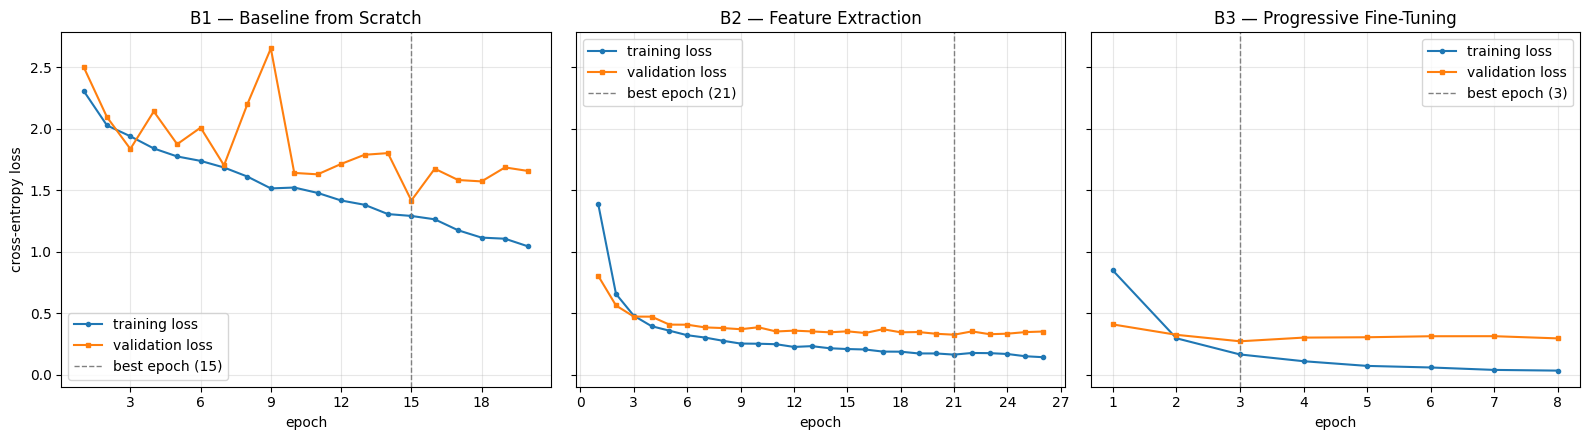

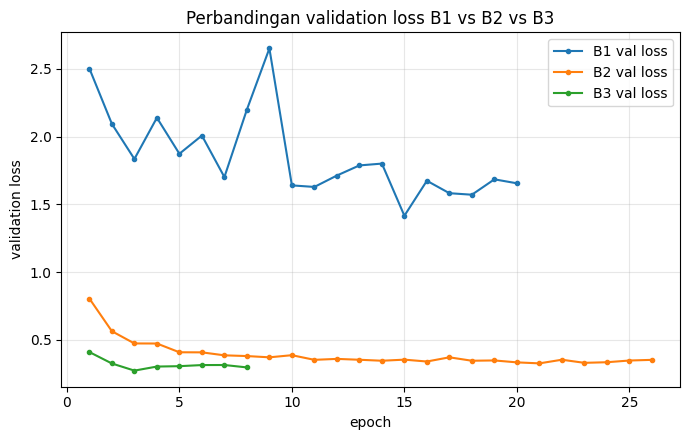

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharey=True)
for ax, rid in zip(axes, ["B1", "B2", "B3"]):
    h = RESULTS[rid]["history"]
    best = RESULTS[rid]["summary"]["best_epoch"]
    ax.plot(h["epoch"], h["train_loss"], marker="o", ms=3, label="training loss")
    ax.plot(h["epoch"], h["val_loss"], marker="s", ms=3, label="validation loss")
    ax.axvline(best, color="gray", ls="--", lw=1, label=f"best epoch ({best})")
    ax.set_title(f"{rid} — {RESULTS[rid]['summary']['condition']}")
    ax.set_xlabel("epoch"); ax.grid(alpha=0.3); ax.legend()
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
axes[0].set_ylabel("cross-entropy loss")
plt.tight_layout()
plt.savefig(FIG_DIR / "c1_loss_curves_B1_B2_B3.png", dpi=150)
plt.show()

plt.figure(figsize=(7, 4.5))
for rid in ["B1", "B2", "B3"]:
    h = RESULTS[rid]["history"]
    plt.plot(h["epoch"], h["val_loss"], marker="o", ms=3, label=f"{rid} val loss")
plt.xlabel("epoch"); plt.ylabel("validation loss"); plt.title("Perbandingan validation loss B1 vs B2 vs B3")
plt.grid(alpha=0.3); plt.legend(); plt.tight_layout()
plt.savefig(FIG_DIR / "c1_val_loss_comparison.png", dpi=150)
plt.show()

## 9. Analisis Augmentasi B4 (bahan C2)
Gap = akurasi train (tanpa augmentasi) − akurasi validasi. Makin besar gap, makin besar overfitting-nya.
Di bagian bawah ada cek B3 vs B4_aug, hasilnya harus identik.

,augmentation,best_epoch,train_acc_clean,val_acc,gap_train_val,val_loss_best,test_f1_macro
run_id,,,,,,,
B4_noaug,False,4,1.0000,0.9094,0.0906,0.2801,0.9156
B4_aug,True,3,0.9748,0.8893,0.0856,0.2724,0.9000


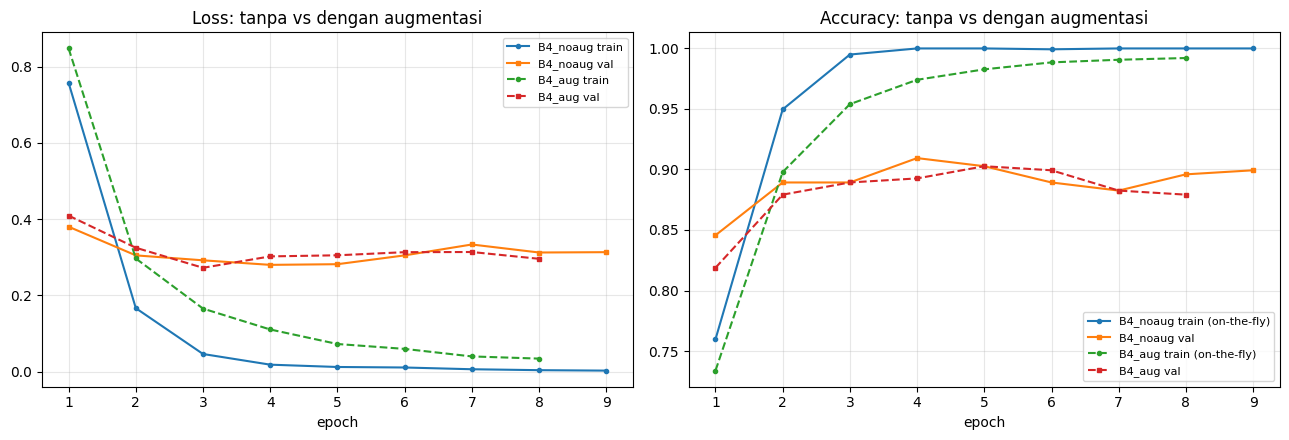

Cek reproduksibilitas B3 vs B4_aug (konfigurasi identik):


,best_epoch,val_acc,test_f1_macro
run_id,,,
B3,3,0.8893,0.9
B4_aug,3,0.8893,0.9


In [19]:
b4 = results_df.set_index("run_id").loc[["B4_noaug", "B4_aug"],
     ["augmentation", "best_epoch", "train_acc_clean", "val_acc", "gap_train_val", "val_loss_best", "test_f1_macro"]]
display(b4)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for rid, style in [("B4_noaug", "-"), ("B4_aug", "--")]:
    h = RESULTS[rid]["history"]
    axes[0].plot(h["epoch"], h["train_loss"], style, marker="o", ms=3, label=f"{rid} train")
    axes[0].plot(h["epoch"], h["val_loss"], style, marker="s", ms=3, label=f"{rid} val")
    axes[1].plot(h["epoch"], h["train_acc"], style, marker="o", ms=3, label=f"{rid} train (on-the-fly)")
    axes[1].plot(h["epoch"], h["val_acc"], style, marker="s", ms=3, label=f"{rid} val")
axes[0].set_title("Loss: tanpa vs dengan augmentasi"); axes[0].set_xlabel("epoch"); axes[0].legend(fontsize=8)
axes[1].set_title("Accuracy: tanpa vs dengan augmentasi"); axes[1].set_xlabel("epoch"); axes[1].legend(fontsize=8)
for ax in axes:
    ax.grid(alpha=0.3)
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
plt.tight_layout()
plt.savefig(FIG_DIR / "c2_b4_augmentation.png", dpi=150)
plt.show()

print("Cek reproduksibilitas B3 vs B4_aug (konfigurasi identik):")
display(results_df.set_index("run_id").loc[["B3", "B4_aug"], ["best_epoch", "val_acc", "test_f1_macro"]])

## 10. Failure Analysis (bahan C3)
Model terbaik dipilih dari val accuracy. Confusion matrix dipakai untuk lihat kelas mana yang paling sering tertukar.

Model terbaik (berdasarkan val accuracy): B5 | test macro-F1 = 0.9423


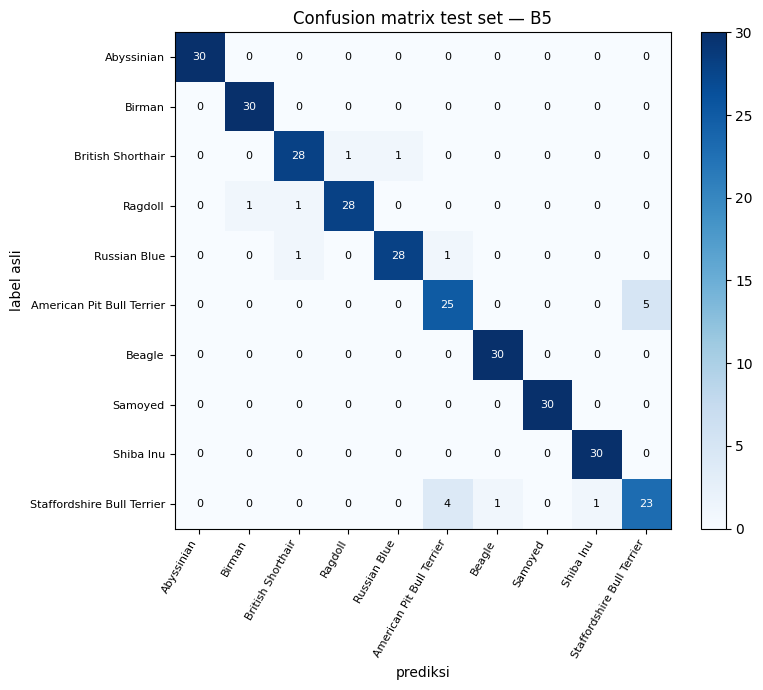

In [20]:
best_run = max(RUN_ORDER, key=lambda r: (RESULTS[r]["summary"]["val_acc"], -RESULTS[r]["summary"]["val_loss_best"]))
print(f"Model terbaik (berdasarkan val accuracy): {best_run} | test macro-F1 = {RESULTS[best_run]['summary']['test_f1_macro']}")

bp = RESULTS[best_run]["preds"]
cm = confusion_matrix(bp["y_true"], bp["y_pred"], labels=range(NUM_CLASSES))
fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(NUM_CLASSES)); ax.set_xticklabels(SELECTED_CLASSES, rotation=60, ha="right", fontsize=8)
ax.set_yticks(range(NUM_CLASSES)); ax.set_yticklabels(SELECTED_CLASSES, fontsize=8)
for i in range(NUM_CLASSES):
    for j in range(NUM_CLASSES):
        ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=8, color="white" if cm[i, j] > cm.max() / 2 else "black")
ax.set_xlabel("prediksi"); ax.set_ylabel("label asli"); ax.set_title(f"Confusion matrix test set — {best_run}")
plt.colorbar(im, fraction=0.046); plt.tight_layout()
plt.savefig(FIG_DIR / "c3_confusion_matrix.png", dpi=150)
plt.show()

Menampilkan maksimal 8 gambar yang salah prediksi, diurutkan dari confidence paling tinggi. Hipotesis penyebabnya dibahas di laporan Part C.

Jumlah kesalahan pada test set: 17 dari 299


,global_idx,true_class,pred_class,confidence,prob_true_class
0,3884,American Pit Bull Terrier,Staffordshire Bull Terrier,0.9702,0.0286
1,1719,Staffordshire Bull Terrier,American Pit Bull Terrier,0.9251,0.0729
2,3900,American Pit Bull Terrier,Staffordshire Bull Terrier,0.9231,0.0456
3,1339,Ragdoll,Birman,0.8702,0.1078
4,1701,Staffordshire Bull Terrier,American Pit Bull Terrier,0.8546,0.1413
5,3965,American Pit Bull Terrier,Staffordshire Bull Terrier,0.8011,0.1171
6,1969,American Pit Bull Terrier,Staffordshire Bull Terrier,0.7875,0.1129
7,4614,British Shorthair,Ragdoll,0.7320,0.2671


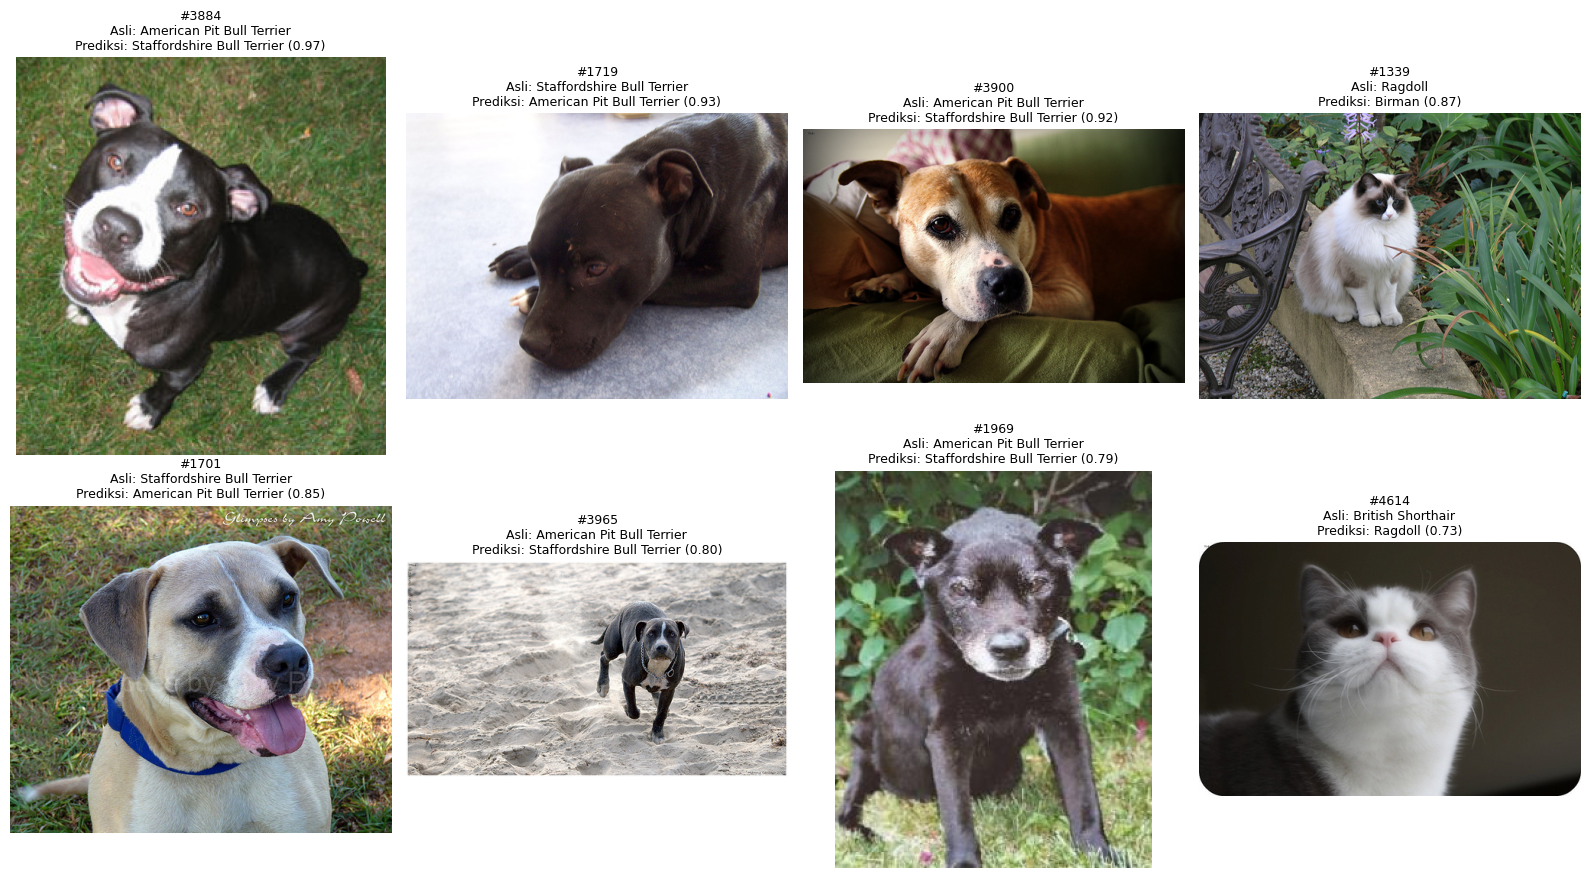

In [21]:
wrong = bp[~bp["correct"].astype(bool)].sort_values("confidence", ascending=False).head(8).reset_index(drop=True)
wrong.to_csv(OUT_DIR / "c3_misclassified.csv", index=False)
print(f"Jumlah kesalahan pada test set: {(~bp['correct'].astype(bool)).sum()} dari {len(bp)}")
display(wrong[["global_idx", "true_class", "pred_class", "confidence", "prob_true_class"]])

if len(wrong):
    ncol = 4
    nrow = int(np.ceil(len(wrong) / ncol))
    fig, axes = plt.subplots(nrow, ncol, figsize=(16, 4.4 * nrow), squeeze=False)
    for ax, (_, r) in zip(axes.flat, wrong.iterrows()):
        img, _ = full_meta[int(r["global_idx"])]
        ax.imshow(img)
        ax.set_title(f"#{int(r['global_idx'])}\nAsli: {r['true_class']}\nPrediksi: {r['pred_class']} ({r['confidence']:.2f})",
                     fontsize=9)
    for ax in axes.flat:
        ax.axis("off")
    plt.tight_layout()
    plt.savefig(FIG_DIR / "c3_misclassified.png", dpi=150)
    plt.show()

## 11. Ringkasan File Output
Daftar file yang dihasilkan notebook ini. Semua file dilampirkan di ZIP dan GitHub, kecuali folder `checkpoints/` karena ukurannya besar.

In [22]:
for p in sorted(OUT_DIR.glob("*")):
    if p.is_file():
        print(f"{p.name:<32} {p.stat().st_size / 1024:8.1f} KB")
print("\nFigures:", [p.name for p in sorted(FIG_DIR.glob('*.png'))])

c3_misclassified.csv                  0.7 KB
config.json                           0.7 KB
history.csv                           9.1 KB
results.csv                           1.6 KB
results.json                          5.7 KB
split_counts.csv                      0.3 KB
split_indices.json                   11.5 KB
table_c1.csv                          0.7 KB
test_predictions.csv                104.0 KB

Figures: ['c1_loss_curves_B1_B2_B3.png', 'c1_val_loss_comparison.png', 'c2_b4_augmentation.png', 'c3_confusion_matrix.png', 'c3_misclassified.png', 'sample_batches.png']
